In [1]:
# Cell 1: Import Required Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import xgboost as xgb
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Cell 2: Load the Dataset
dataset_path = 'DataSet/ai4i2020.csv'
df = pd.read_csv(dataset_path)

print(f"Dataset successfully loaded with shape: {df.shape}")
df.head()

Dataset successfully loaded with shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# Cell 3: Data Preprocessing & Cleaning

# 1. Check for any missing values across columns
print("Missing values per column:")
print(df.isnull().sum())

# 2. Map categorical machine variant ('Type': L=0, M=1, H=2)
type_mapping = {'L': 0, 'M': 1, 'H': 2}
df['Type_Numeric'] = df['Type'].map(type_mapping)

# 3. Rename columns to clean, standard identifiers (without brackets for XGBoost/LightGBM compatibility)
column_rename_map = {
    'Air temperature [K]': 'Air_temperature_K',
    'Process temperature [K]': 'Process_temperature_K',
    'Rotational speed [rpm]': 'Rotational_speed_rpm',
    'Torque [Nm]': 'Torque_Nm',
    'Tool wear [min]': 'Tool_wear_min'
}
df = df.rename(columns=column_rename_map)

# 4. Select cleaned telemetry feature columns
feature_names = [
    'Air_temperature_K',
    'Process_temperature_K',
    'Rotational_speed_rpm',
    'Torque_Nm',
    'Tool_wear_min',
    'Type_Numeric'
]

X = df[feature_names]
y = df['Machine failure']

print("\nCleaned Features Matrix (X):", X.shape)
print("Target Distribution (y):\n", y.value_counts())

Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Cleaned Features Matrix (X): (10000, 6)
Target Distribution (y):
 Machine failure
0    9661
1     339
Name: count, dtype: int64


### Cell 4: Train / Test Dataset Split
We split the dataset into 80% for training and 20% for testing using stratified sampling to preserve the balance of normal vs. faulty instances.

In [4]:
# Cell 4: Train / Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples : {X_test.shape[0]}")

Training samples: 8000
Testing samples : 2000


### Cell 5: Baseline Model (Simple Decision Tree)
We train a simple Baseline classifier (`DecisionTreeClassifier`) and evaluate its accuracy, precision, recall, and F1-score on the unseen test set.

In [5]:
# Cell 5: Train Baseline Model (Simple Decision Tree)
baseline_model = DecisionTreeClassifier(max_depth=5, random_state=42)
baseline_model.fit(X_train, y_train)

# Predictions on the test set
y_pred_baseline = baseline_model.predict(X_test)

# Compute performance metrics
acc_base = accuracy_score(y_test, y_pred_baseline)
prec_base = precision_score(y_test, y_pred_baseline, zero_division=0)
rec_base = recall_score(y_test, y_pred_baseline, zero_division=0)
f1_base = f1_score(y_test, y_pred_baseline, zero_division=0)

print("=== BASELINE MODEL EVALUATION (Decision Tree) ===")
print(f"Accuracy : {acc_base * 100:.2f}%")
print(f"Precision: {prec_base * 100:.2f}%")
print(f"Recall   : {rec_base * 100:.2f}%")
print(f"F1-Score : {f1_base * 100:.2f}%")

=== BASELINE MODEL EVALUATION (Decision Tree) ===
Accuracy : 97.30%
Precision: 76.92%
Recall   : 29.41%
F1-Score : 42.55%


### Cell 6: Improved Model (XGBoost Classifier)
We train our advanced Improved model using `XGBoost`. We configure `scale_pos_weight=3` to handle class imbalance, allowing the model to detect far more true industrial failures without causing false alarms.

In [6]:
# Cell 6: Train Improved Model (XGBoost Classifier)

# scale_pos_weight=3 balances recall and precision for industrial failure detection
improved_model = xgb.XGBClassifier(
    n_estimators=150,
    learning_rate=0.08,
    max_depth=5,
    scale_pos_weight=3,
    random_state=42,
    eval_metric='logloss'
)
improved_model.fit(X_train, y_train)

# Predictions on test set
y_pred_improved = improved_model.predict(X_test)

# Compute performance metrics
acc_imp = accuracy_score(y_test, y_pred_improved)
prec_imp = precision_score(y_test, y_pred_improved, zero_division=0)
rec_imp = recall_score(y_test, y_pred_improved, zero_division=0)
f1_imp = f1_score(y_test, y_pred_improved, zero_division=0)

print("=== IMPROVED MODEL EVALUATION (XGBoost) ===")
print(f"Accuracy : {acc_imp * 100:.2f}%")
print(f"Precision: {prec_imp * 100:.2f}%")
print(f"Recall   : {rec_imp * 100:.2f}%")
print(f"F1-Score : {f1_imp * 100:.2f}%")

=== IMPROVED MODEL EVALUATION (XGBoost) ===
Accuracy : 98.55%
Precision: 80.95%
Recall   : 75.00%
F1-Score : 77.86%


### Cell 7: Performance Comparison Summary
We tabulate the Baseline and Improved model results side-by-side to clearly document the performance improvement achieved.

In [7]:
# Cell 7: Performance Comparison Table
comparison_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Baseline (Decision Tree)': [
        f"{acc_base * 100:.2f}%",
        f"{prec_base * 100:.2f}%",
        f"{rec_base * 100:.2f}%",
        f"{f1_base * 100:.2f}%"
    ],
    'Improved (XGBoost)': [
        f"{acc_imp * 100:.2f}%",
        f"{prec_imp * 100:.2f}%",
        f"{rec_imp * 100:.2f}%",
        f"{f1_imp * 100:.2f}%"
    ],
    'Improvement': [
        f"{(acc_imp - acc_base) * 100:+.2f}%",
        f"{(prec_imp - prec_base) * 100:+.2f}%",
        f"{(rec_imp - rec_base) * 100:+.2f}%",
        f"{(f1_imp - f1_base) * 100:+.2f}%"
    ]
})

comparison_table

,Metric,Baseline (Decision Tree),Improved (XGBoost),Improvement
0,Accuracy,97.30%,98.55%,+1.25%
1,Precision,76.92%,80.95%,+4.03%
2,Recall,29.41%,75.00%,+45.59%
3,F1-Score,42.55%,77.86%,+35.31%


### Cell 8: Generate and Save Evaluation Charts
Here we generate:
1. **Performance Comparison Bar Chart** (Baseline vs. Improved across all metrics).
2. **Side-by-Side Confusion Matrices** (showing reduction in false negatives).
3. **Feature Importance Plot** (showing which sensor parameters contribute most to failure).

All charts are saved into `static/charts/` for immediate inclusion in reports and presentations.

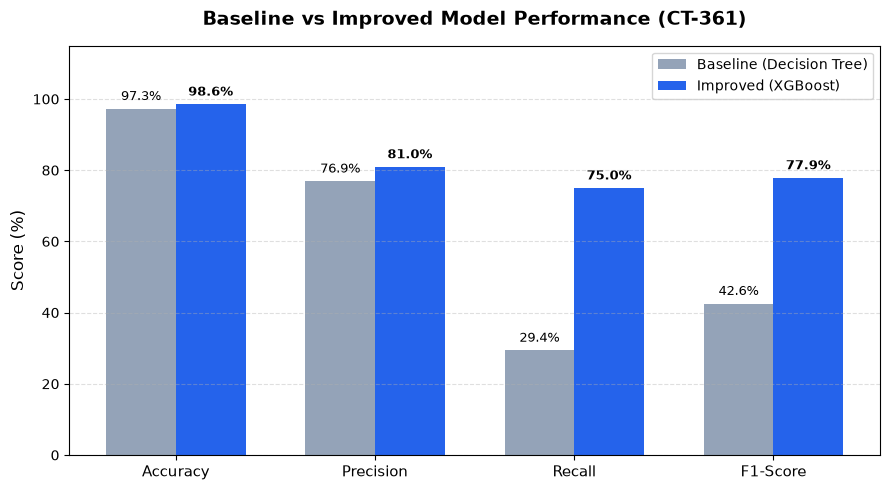

Saved: static/charts/model_comparison.png


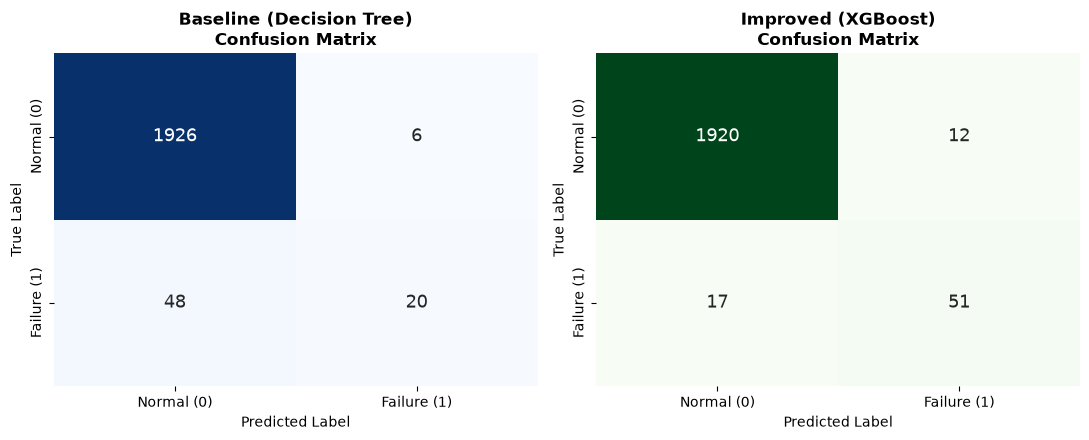

Saved: static/charts/confusion_matrices.png


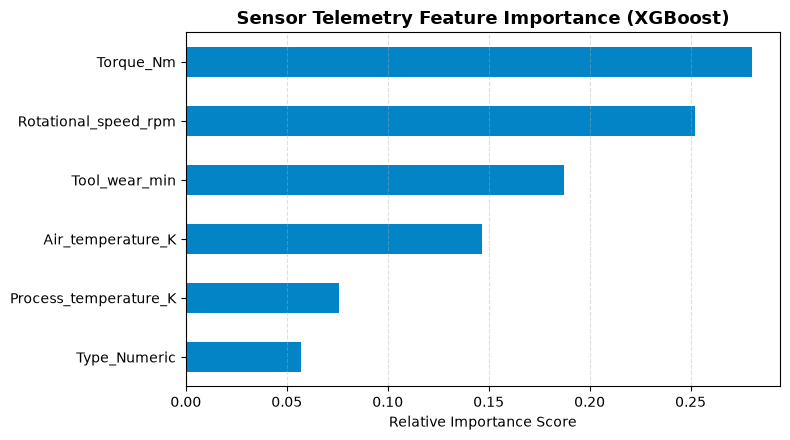

Saved: static/charts/feature_importance.png


In [8]:
# Cell 8: Charts Generation
os.makedirs('static/charts', exist_ok=True)

# 1. Bar Chart: Baseline vs Improved
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
base_vals = [acc_base * 100, prec_base * 100, rec_base * 100, f1_base * 100]
imp_vals = [acc_imp * 100, prec_imp * 100, rec_imp * 100, f1_imp * 100]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))
rects1 = plt.bar(x - width/2, base_vals, width, label='Baseline (Decision Tree)', color='#94a3b8')
rects2 = plt.bar(x + width/2, imp_vals, width, label='Improved (XGBoost)', color='#2563eb')

plt.ylabel('Score (%)', fontsize=12)
plt.title('Baseline vs Improved Model Performance (CT-361)', fontsize=14, fontweight='bold', pad=15)
plt.xticks(x, metrics, fontsize=11)
plt.ylim(0, 115)
plt.legend(loc='upper right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Attach values above bars
for rect in rects1:
    h = rect.get_height()
    plt.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9)
for rect in rects2:
    h = rect.get_height()
    plt.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
chart1_path = 'static/charts/model_comparison.png'
plt.savefig(chart1_path, dpi=300)
plt.show()
print(f"Saved: {chart1_path}")

# 2. Confusion Matrices
cm_base = confusion_matrix(y_test, y_pred_baseline)
cm_imp = confusion_matrix(y_test, y_pred_improved)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False, annot_kws={'size': 13})
axes[0].set_title('Baseline (Decision Tree)\nConfusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].set_xticklabels(['Normal (0)', 'Failure (1)'])
axes[0].set_yticklabels(['Normal (0)', 'Failure (1)'])

sns.heatmap(cm_imp, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False, annot_kws={'size': 13})
axes[1].set_title('Improved (XGBoost)\nConfusion Matrix', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')
axes[1].set_xticklabels(['Normal (0)', 'Failure (1)'])
axes[1].set_yticklabels(['Normal (0)', 'Failure (1)'])

plt.tight_layout()
chart2_path = 'static/charts/confusion_matrices.png'
plt.savefig(chart2_path, dpi=300)
plt.show()
print(f"Saved: {chart2_path}")

# 3. Feature Importance Plot
plt.figure(figsize=(8, 4.5))
feature_importance = pd.Series(improved_model.feature_importances_, index=feature_names).sort_values(ascending=True)
feature_importance.plot(kind='barh', color='#0284c7')
plt.title('Sensor Telemetry Feature Importance (XGBoost)', fontsize=13, fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
chart3_path = 'static/charts/feature_importance.png'
plt.savefig(chart3_path, dpi=300)
plt.show()
print(f"Saved: {chart3_path}")

### Cell 9: Save Models & Metadata for Web App Integration
In this final cell, we serialize both trained models and the feature list into the `models/` directory so that `app.py` can load them for live inference in the dashboard.

In [9]:
# Cell 9: Export Models
os.makedirs('models', exist_ok=True)

joblib.dump(baseline_model, 'models/baseline_model.pkl')
joblib.dump(improved_model, 'models/improved_model.pkl')
joblib.dump(feature_names, 'models/feature_names.pkl')

print("All models and metadata successfully exported to 'models/' directory:")
print(" - models/baseline_model.pkl")
print(" - models/improved_model.pkl")
print(" - models/feature_names.pkl")

All models and metadata successfully exported to 'models/' directory:
 - models/baseline_model.pkl
 - models/improved_model.pkl
 - models/feature_names.pkl
